# COVID19 Government Measures and Progression of the Pandemic

In this notebook, I will attempt to train ML models to solve the *binary classification* task of predicting whether or not a country's covid cases will surge,i.e. increase by 25%, in two weeks.

## Running this notebook

From the project root, run `uv sync` and select the `.venv` Python interpreter
as this notebook's kernel. Alternatively, install with `python -m pip install -e .`.
The reusable models and helpers are imported from `covidml`; datasets and figure
outputs resolve from the project root when running here or from `notebooks/`.
The hyperparameter searches below can take a while to complete.


## Initial Dataset Loading and Cleaning

In [1]:
import os

# Set before importing numerical libraries to avoid macOS/OpenMP thread issues.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from covidml.paths import find_project_root

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "datasets"
FIGURES_DIR = PROJECT_ROOT / "figures"

measures_dataset = pd.read_excel(DATA_DIR / "acaps_covid19_government_measures_dataset.xlsx", sheet_name="Dataset")
# For easier downstream processing renaming the columns to follow owid conventions
measures_dataset.columns = measures_dataset.columns.str.lower()
if 'iso' in measures_dataset.columns:
    measures_dataset = measures_dataset.rename(columns={'iso': 'iso_code'})
if 'country' in measures_dataset.columns:
    measures_dataset = measures_dataset.rename(columns={'country': 'location'})
if 'date_implemented' in measures_dataset.columns:
    measures_dataset = measures_dataset.rename(columns={'date_implemented': 'date'})
observables_dataset = pd.read_csv(DATA_DIR / "owid-covid-data.csv")

First, I casted the date objects to integer timesteps for easier processing

In [2]:
observables_dataset["date"] = pd.to_datetime(observables_dataset['date'])
measures_dataset["date"] = pd.to_datetime(measures_dataset['date'])
min_date = observables_dataset['date'].min()
observables_dataset['time_step'] = (observables_dataset['date'] - min_date).dt.days + 1
measures_dataset['time_step'] = (measures_dataset['date'] - min_date).dt.days + 1

Since the ACAPS Government Measures dataset stopped collecting data around the one year mark, we will focus only on this part of the series.

In [3]:
measures_dataset["time_step"].max()

np.float64(381.0)

In [4]:
MAX_TIME_STEP = 385
observables_dataset = observables_dataset[(observables_dataset["time_step"] <= MAX_TIME_STEP)].copy()
measures_dataset = measures_dataset[(measures_dataset["time_step"] <= MAX_TIME_STEP)].dropna(subset=["time_step"]).copy()
print(f"Observables: {len(observables_dataset)} rows | Max Time Step: {observables_dataset['time_step'].max()}")
print(f"Measures: {len(measures_dataset)} rows | Max Time Step: {int(measures_dataset['time_step'].max())}")

Observables: 95841 rows | Max Time Step: 385
Measures: 23630 rows | Max Time Step: 381


## Defining the scope

Because our target variable is based on confirmed case surges, the biggest potential confounder is a country's testing capacity. A sudden spike in cases might simply represent an influx of test kits rather than a viral surge.

To ensure our model learns actual epidemiological trends rather than testing artifacts, we need frequent, reliable reporting of testing metrics. My analysis showed that by setting a 80% completeness threshold for daily testing data (new_tests_smoothed_per_thousand), we are left with 56 countries to train the models on.

In [5]:
testing_completeness = (
    observables_dataset.groupby("iso_code")["new_tests_smoothed_per_thousand"]
    .apply(lambda x: x.notna().mean())
    .reset_index(name="testing_reporting_rate")
)
final_cohort = testing_completeness[testing_completeness["testing_reporting_rate"] >= 0.80]["iso_code"].tolist()
print(f"Final ML Cohort Size: {len(final_cohort)} countries")
print(final_cohort)

ml_observables = observables_dataset[observables_dataset['iso_code'].isin(final_cohort)].copy()
ml_measures = measures_dataset[measures_dataset['iso_code'].isin(final_cohort)].copy()

Final ML Cohort Size: 56 countries
['ALB', 'ARE', 'ARG', 'ARM', 'AUS', 'BEL', 'BHR', 'BLR', 'BOL', 'CAN', 'CRI', 'DNK', 'ECU', 'EST', 'ETH', 'FIN', 'FJI', 'GRC', 'GTM', 'GUM', 'HKG', 'HRV', 'HUN', 'IND', 'ISL', 'ISR', 'ITA', 'JPN', 'KAZ', 'KEN', 'KOR', 'LKA', 'LUX', 'LVA', 'MAR', 'MEX', 'MYS', 'NPL', 'NZL', 'PAK', 'PAN', 'POL', 'PRI', 'PRT', 'PRY', 'RUS', 'SAU', 'SEN', 'SRB', 'SVK', 'SVN', 'TGO', 'THA', 'TWN', 'USA', 'ZAF']


### Handpicking the Interesting Measures

In [6]:
ml_measures.head()

,id,iso_code,location,region,admin_level_name,pcode,log_type,category,measure,targeted_pop_group,comments,non_compliance,date,source,source_type,link,entry_date,alternative source,time_step
59,5390,ALB,Albania,Europe,NaN,NaN,Introduction / extension of measures,Public health measures,Strengthening the public health system,NaN,Order of the Minister responsible for health: ...,Not applicable,2020-01-24,"Albanian Government ""legal acts""",Government,https://coronavirus.al/akte-ligjore/,2020-04-15,NaN,24.0
60,5392,ALB,Albania,Europe,NaN,NaN,Introduction / extension of measures,Public health measures,Other public health measures enforced,checked,Order of the Minister responsible for health n...,Not available,2020-01-24,"Albanian Government ""legal acts""",Government,https://coronavirus.al/akte-ligjore/,2020-04-15,NaN,24.0
61,5391,ALB,Albania,Europe,NaN,NaN,Introduction / extension of measures,Public health measures,Strengthening the public health system,NaN,Order of the Minister responsible for health n...,Not available,2020-01-31,"Albanian Government ""legal acts""",Government,https://coronavirus.al/akte-ligjore/,2020-04-15,NaN,31.0
62,5393,ALB,Albania,Europe,NaN,NaN,Introduction / extension of measures,Public health measures,Strengthening the public health system,NaN,Order of the Minister responsible for health n...,Not available,2020-02-26,"Albanian Government ""legal acts""",Government,https://coronavirus.al/akte-ligjore/,2020-04-15,NaN,57.0
63,5394,ALB,Albania,Europe,NaN,NaN,Introduction / extension of measures,Governance and socio-economic measures,Limit product imports/exports,NaN,Order of the Minister responsible for health n...,Not available,2020-03-08,"Albanian Government ""legal acts""",Government,https://coronavirus.al/akte-ligjore/,2020-04-15,NaN,68.0


In [7]:
# Can be uncommented to see many different measure types.
"""
print(len(set(measures_dataset["measure"])))
for m in set(ml_measures["measure"]):
    print(f"- {m}")
""";

Since some of these measures are vague and country dependent and possibly inconsequential, I've decided to keep only specific tags from this long list, namely:

- Partial lockdown
- Full lockdown
- Isolation and quarantine policies
- State of emergency declared
- Curfews

As I believe these measures are the harshest of the list and would possibly be the most consequential for the modelling problem. I really didn't want to lose the possible signal to measures like facebook posts. From these measures I will create some features.

In [8]:
picked_measures = ["Partial lockdown", "Full lockdown", "Isolation and quarantine policies", "State of emergency declared", "Curfews"]
filtered_measures = ml_measures[ml_measures["measure"].isin(picked_measures)]
measure_counts = (
    filtered_measures.groupby(["iso_code", "measure"])
    .size()
    .reset_index(name="implementation_count")
)
sample_comments = (
    filtered_measures.groupby(["iso_code", "measure"])["comments"]
    .apply(lambda x: x.sample(1, random_state=42).iloc[0] if not x.empty else "No comment")
    .reset_index(name="sample_comment")
)
summary_report = pd.merge(measure_counts, sample_comments, on=["iso_code", "measure"])

In [9]:
print(final_cohort)

['ALB', 'ARE', 'ARG', 'ARM', 'AUS', 'BEL', 'BHR', 'BLR', 'BOL', 'CAN', 'CRI', 'DNK', 'ECU', 'EST', 'ETH', 'FIN', 'FJI', 'GRC', 'GTM', 'GUM', 'HKG', 'HRV', 'HUN', 'IND', 'ISL', 'ISR', 'ITA', 'JPN', 'KAZ', 'KEN', 'KOR', 'LKA', 'LUX', 'LVA', 'MAR', 'MEX', 'MYS', 'NPL', 'NZL', 'PAK', 'PAN', 'POL', 'PRI', 'PRT', 'PRY', 'RUS', 'SAU', 'SEN', 'SRB', 'SVK', 'SVN', 'TGO', 'THA', 'TWN', 'USA', 'ZAF']


In [10]:
summary_report[summary_report["iso_code"].isin(["NPL"])]

,iso_code,measure,implementation_count,sample_comment
121,NPL,Curfews,1,No pedestrians or vehicles will be allowed out...
122,NPL,Full lockdown,5,Extension of lockdown period to April 15
123,NPL,Isolation and quarantine policies,6,All arrivals into Nepal 14 day self-quarantine
124,NPL,Partial lockdown,14,Biratnagar has reimposed a lockdown across the...


## The Main Dataset

Now what we need to do a left join on ISO code and the time step as they should uniquely identify a point in our timeseries. But before that we need to make sure that the measures table has the tuple as its key as well.

In [11]:
# (iso_code, time_step) is strictly unique, if multiple measures happen on the same day, this creates separate columns for them.
filtered_measures["measure_active"] = 1
pivoted_measures = filtered_measures.pivot_table(
    index=["iso_code", "time_step"], 
    columns="measure", 
    values="measure_active", 
    fill_value=0
).reset_index()
pivoted_measures.columns.name = None 

dataset = pd.merge(
    ml_observables, 
    pivoted_measures, 
    on=["iso_code", "time_step"], 
    how="left"
)
for col in picked_measures:
    dataset[col] = dataset[col].fillna(0).astype(int)

print(f"Dataset shape after merge: {dataset.shape}")

Dataset shape after merge: (21308, 73)


In [12]:
dataset.head()

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million,time_step,Curfews,Full lockdown,Isolation and quarantine policies,Partial lockdown,State of emergency declared
0,ALB,Europe,Albania,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,NaN,NaN,NaN,5,0,0,0,0,0
1,ALB,Europe,Albania,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,NaN,NaN,NaN,6,0,0,0,0,0
2,ALB,Europe,Albania,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,NaN,NaN,NaN,7,0,0,0,0,0
3,ALB,Europe,Albania,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,NaN,NaN,NaN,8,0,0,0,0,0
4,ALB,Europe,Albania,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,NaN,NaN,NaN,9,0,0,0,0,0


### Features

After consideration of the available features, some features were dropped. General rules in this selection are:
- pick features that are "normalized" instead of absolute counts (cases per million instead of cases), 
- use daily values instead of weekly ones (weekly icu admissions vs icu patients), 
- use smoothed values instead impulsive ones to get rid reporting artifacts, features not available at a given time step (excess deaths calculated after)
- drop redundant features that would just introduce biases (median age and aged over 65 are basically the same feature after normalization)
- drop features regarding vaccination data as they only started after time step 360 meaning our model at training time will not have access to them

Resulting features are:
- new_cases_smoothed_per_million, total_cases_per_million
- new_deaths_smoothed_per_million, total_deaths_per_million
- new_tests_smoothed_per_thousand, total_tests_per_thousand, positive_rate
- reproduction_rate
- stringency_index
And country statistics that are constant through the time series:
- population_density, aged_65_older, gdp_per_capita, extreme_poverty, life_expectancy
- cardiovasc_death_rate, diabetes_prevalence, hospital_beds_per_thousand

To this we will add features extracted from the ACAPS data, the basic idea is to get from the impulse train to features that tell:
- how long has it been since last harsh measure
- how many measures were implemented in the last 90 days

Of course one problem still is there is differences between countries in reporting and scale of these features but considering only the harshest ones might mitigate this fact.


In [13]:
dataset = dataset.sort_values(["iso_code", "time_step"]).copy()
# Mark the days that have at least a single measure implemented, 
# forward fill and subtract from the current timestep to get day since last measure
dataset["harsh_measure_today"] = dataset[picked_measures].max(axis=1)
dataset["last_trigger_step"] = dataset["time_step"].where(dataset["harsh_measure_today"] == 1)
dataset["last_trigger_step"] = dataset.groupby("iso_code")["last_trigger_step"].ffill()
dataset["days_since_last_harsh_measure"] = dataset["time_step"] - dataset["last_trigger_step"]
dataset["days_since_last_harsh_measure"] = dataset["days_since_last_harsh_measure"].fillna(999)

# Use a rolling 90-day sum, grouped by country, to count recent interventions
dataset["total_harsh_measure_today"] = dataset[picked_measures].max(axis=1)
dataset["active_harsh_measures_90d"] = dataset.groupby('iso_code')['total_harsh_measure_today'].transform(
    lambda x: x.rolling(window=90, min_periods=1).sum()
)

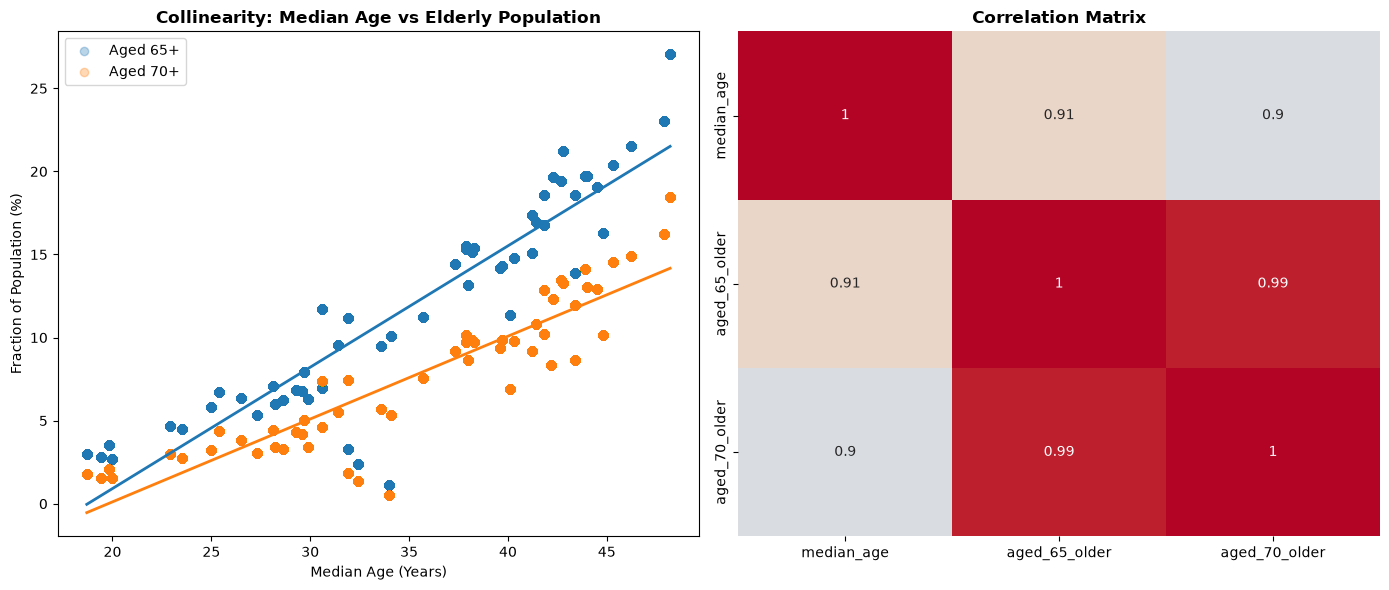

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
sns.regplot(
    data=dataset,
    x="median_age",
    y="aged_65_older",
    ax=ax1,
    scatter_kws={"alpha": 0.3},
    line_kws={"linewidth": 2},
    label="Aged 65+",
)
sns.regplot(
    data=dataset,
    x="median_age",
    y="aged_70_older",
    ax=ax1,
    scatter_kws={"alpha": 0.3},
    line_kws={"linewidth": 2},
    label="Aged 70+",
)

ax1.set_title("Collinearity: Median Age vs Elderly Population", fontweight="bold")
ax1.set_xlabel("Median Age (Years)")
ax1.set_ylabel("Fraction of Population (%)")
ax1.legend(loc="upper left", frameon=True)

# Heatmap for correlation matrix
age_cols = ["median_age", "aged_65_older", "aged_70_older"]
corr_matrix = dataset[age_cols].corr()

sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", vmin=0.8, vmax=1.0, ax=ax2, cbar=False
)
ax2.set_title("Correlation Matrix", fontweight="bold")

plt.tight_layout()
plt.show()

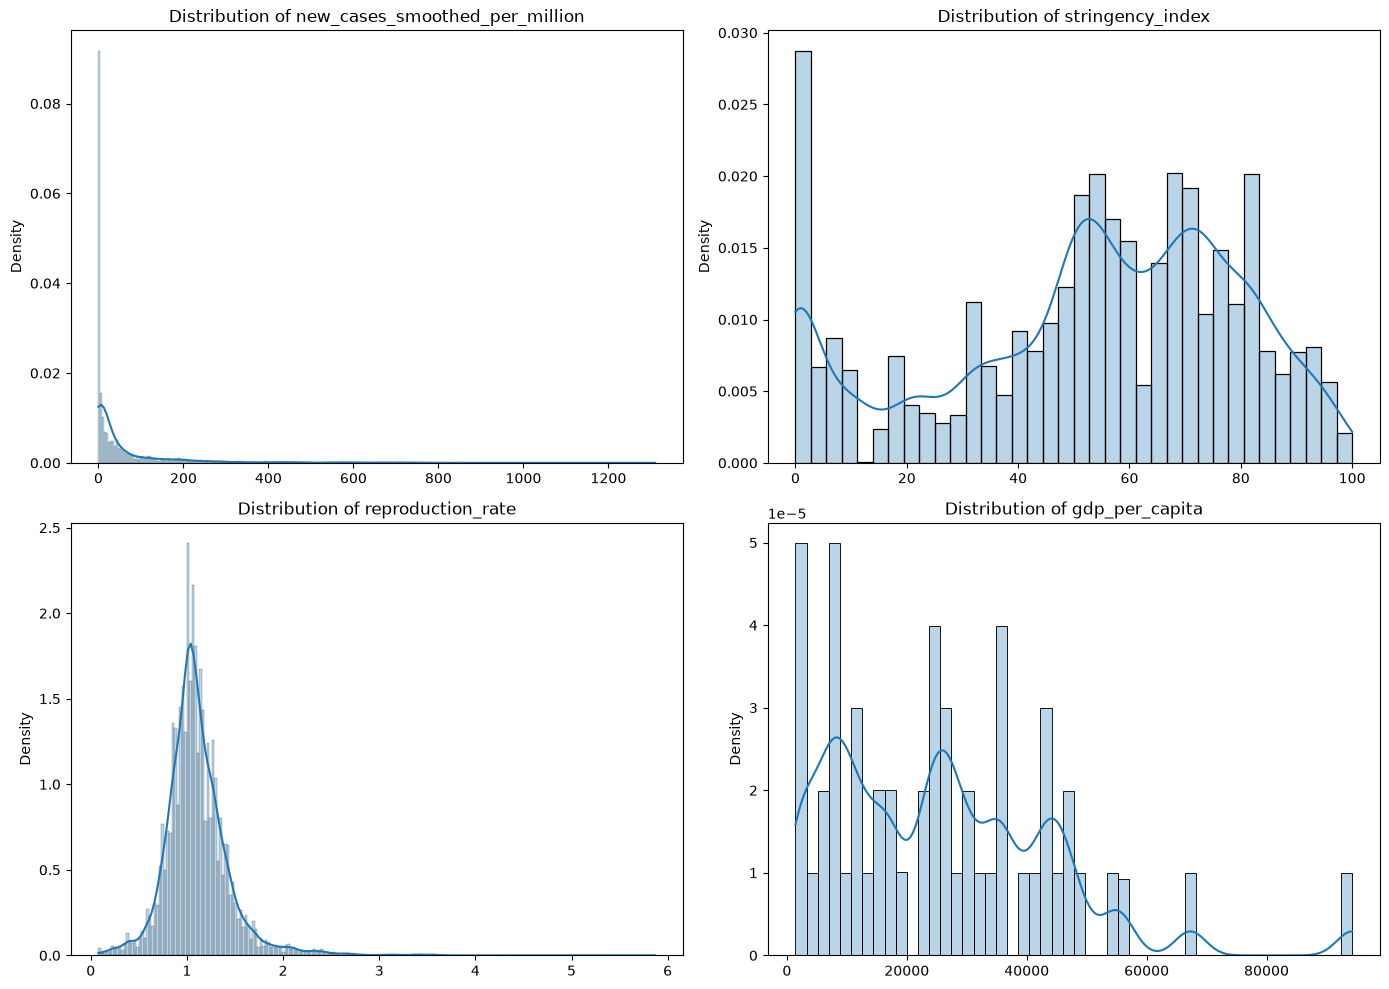

In [15]:
# Select a subset of diverse features to inspect
sample_features = [
    "new_cases_smoothed_per_million",
    "stringency_index",
    "reproduction_rate",
    "gdp_per_capita",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(sample_features):
    # Combine KDE and Boxplot concepts using a Violin plot or Hist + KDE
    sns.histplot(
        data=dataset, x=col, kde=True, ax=axes[i], stat="density", alpha=0.3
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

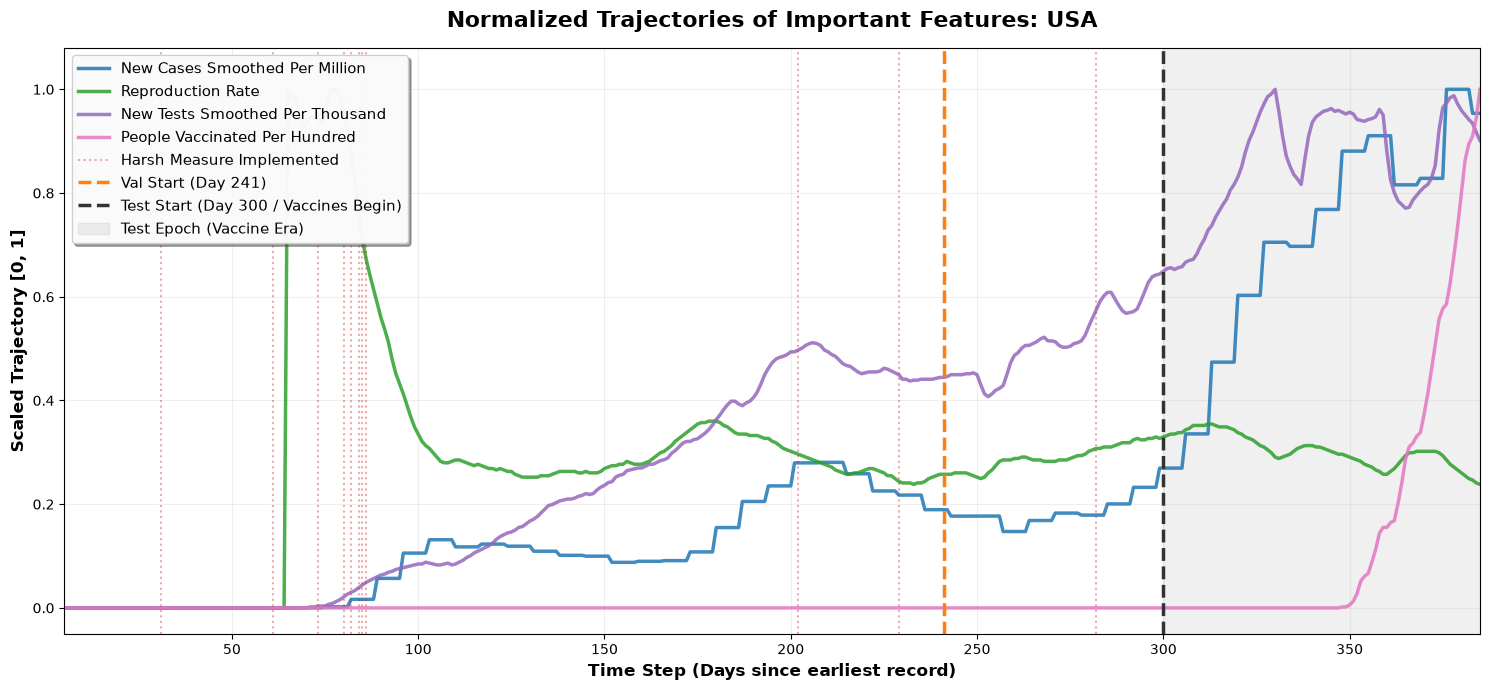

In [16]:
from covidml.visualization import pick_series

features_to_plot = [
    "new_cases_smoothed_per_million",  # The main underlying curve we base our target on
    "reproduction_rate",               # #1 Most decisive XGBoost feature
    "new_tests_smoothed_per_thousand", # Cohort inclusion filter metric
    "people_vaccinated_per_hundred"    # Demonstrates post-Day-300 domain shift
]

pick_series('USA', features_to_plot, dataset, picked_measures)

In [17]:
features = ["iso_code", "time_step",
            "new_cases_smoothed_per_million", "total_cases_per_million",
            "new_deaths_smoothed_per_million", "total_deaths_per_million",
            "new_tests_smoothed_per_thousand", "total_tests_per_thousand", "positive_rate",
            "reproduction_rate", "stringency_index", "population_density", "aged_65_older", 
            "gdp_per_capita", "extreme_poverty", "life_expectancy", "cardiovasc_death_rate", 
            "diabetes_prevalence", "hospital_beds_per_thousand", 
            "days_since_last_harsh_measure", "active_harsh_measures_90d"]
dataset = dataset[features].copy()

### Target Variable

In [18]:
dataset["cases_14d_future"] = dataset.groupby("iso_code")["new_cases_smoothed_per_million"].shift(-14)
dataset["target_surge"] = np.where(dataset["cases_14d_future"] >= (dataset["new_cases_smoothed_per_million"] * 1.25), 1, 0)
dataset = dataset.dropna(subset=['cases_14d_future']).copy()
dataset = dataset.drop(columns=['cases_14d_future'])

Text(0.5, 1.0, 'Correlation Matrix')

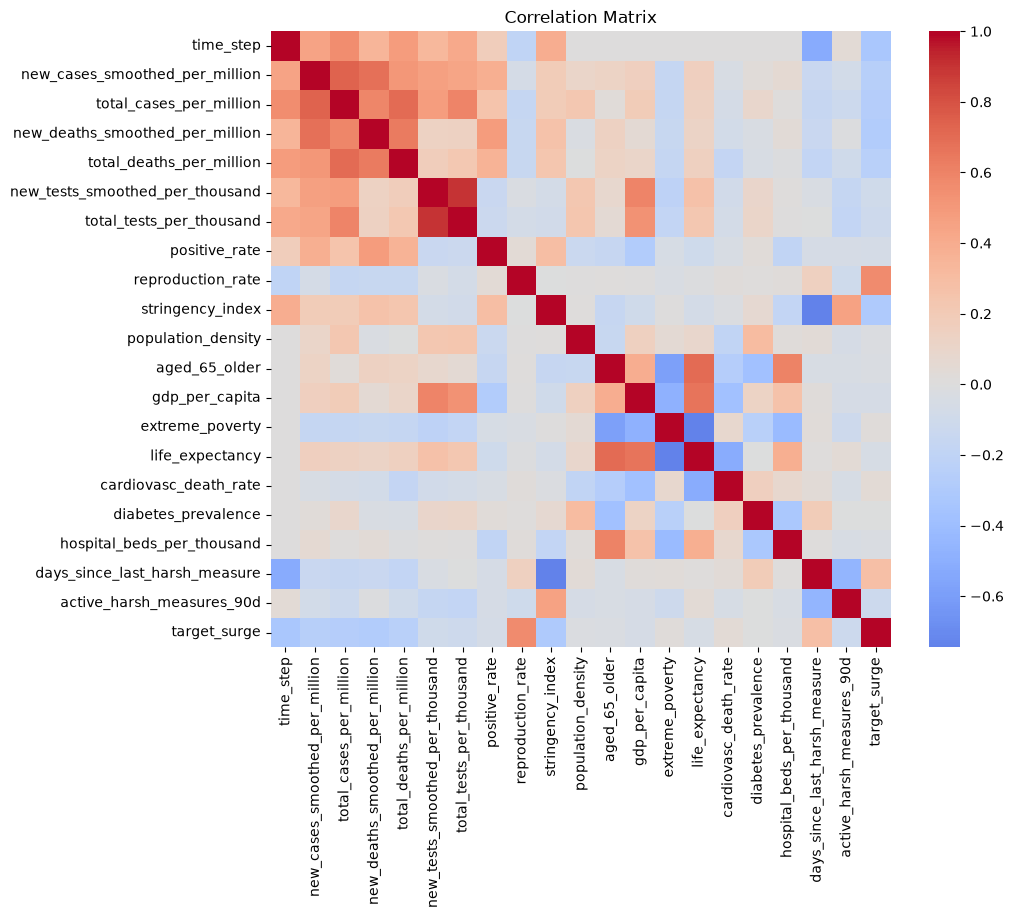

In [19]:
plt.figure(figsize=(10, 8))
corr_matrix = dataset.drop(columns=["iso_code"]).corr()
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Matrix")

Class 0 (No Surge): 48.25%
Class 1 (Surge):    51.75%


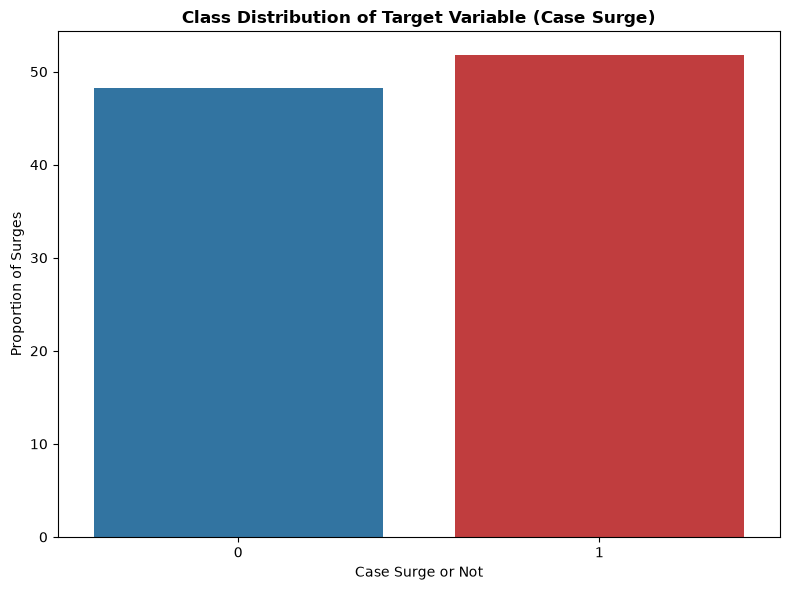

In [20]:
surge_counts = dataset['target_surge'].value_counts(normalize=True) * 100
print(f"Class 0 (No Surge): {surge_counts[0]:.2f}%")
print(f"Class 1 (Surge):    {surge_counts[1]:.2f}%")

plt.figure(figsize=(8, 6))
ax = sns.countplot(
    data=dataset, 
    x='target_surge',
    hue='target_surge',
    palette=['#1f77b4', '#d62728'],
    legend=False,
    stat="percent"
)

plt.title("Class Distribution of Target Variable (Case Surge)", fontweight="bold")
plt.xlabel("Case Surge or Not")
plt.ylabel("Proportion of Surges")


plt.tight_layout()
plt.show()

The target variable is basically a uniformly distributed binary variable, I believe this is great for a classification task.

### Final fixes for the dataset

In [21]:
dataset = dataset.dropna(subset=['new_cases_smoothed_per_million']).copy()
# Calculate the percentage of missing values for each column
missing_percentages = (dataset[features].isnull().sum() / len(dataset)) * 100
print("Missing Data Percentage per Feature:")
print(missing_percentages.sort_values(ascending=False))

Missing Data Percentage per Feature:
reproduction_rate                  23.800020
extreme_poverty                    22.229045
positive_rate                      20.560843
total_tests_per_thousand           17.214205
new_tests_smoothed_per_thousand    13.714052
hospital_beds_per_thousand          5.557261
stringency_index                    5.434449
gdp_per_capita                      1.852420
new_deaths_smoothed_per_million     0.005117
days_since_last_harsh_measure       0.000000
diabetes_prevalence                 0.000000
cardiovasc_death_rate               0.000000
life_expectancy                     0.000000
iso_code                            0.000000
aged_65_older                       0.000000
population_density                  0.000000
time_step                           0.000000
total_deaths_per_million            0.000000
total_cases_per_million             0.000000
new_cases_smoothed_per_million      0.000000
active_harsh_measures_90d           0.000000
dtype: float64


In [22]:
impute_cols = [col for col in dataset.columns if col not in ['iso_code', 'time_step']]
# Forward fill any gaps, per country basis
dataset[impute_cols] = dataset.groupby('iso_code')[impute_cols].ffill()
# Set leading NaNs as 0s
dataset = dataset.fillna(0)

In [23]:
# Calculate the percentage of missing values for each column
missing_percentages = (dataset[features].isnull().sum() / len(dataset)) * 100
print("Missing Data Percentage per Feature:")
print(missing_percentages.sort_values(ascending=False))

Missing Data Percentage per Feature:
iso_code                           0.0
population_density                 0.0
days_since_last_harsh_measure      0.0
hospital_beds_per_thousand         0.0
diabetes_prevalence                0.0
cardiovasc_death_rate              0.0
life_expectancy                    0.0
extreme_poverty                    0.0
gdp_per_capita                     0.0
aged_65_older                      0.0
stringency_index                   0.0
time_step                          0.0
reproduction_rate                  0.0
positive_rate                      0.0
total_tests_per_thousand           0.0
new_tests_smoothed_per_thousand    0.0
total_deaths_per_million           0.0
new_deaths_smoothed_per_million    0.0
total_cases_per_million            0.0
new_cases_smoothed_per_million     0.0
active_harsh_measures_90d          0.0
dtype: float64


## Machine Learning

### Data Split

We have access to 371 time points, we will split roughly 80% for training and 20% for testing

In [24]:
TRAIN_END_DAY = 300
train_all_df = dataset[dataset['time_step'] <= TRAIN_END_DAY].copy()
test_df  = dataset[dataset['time_step'] > TRAIN_END_DAY].copy()
feature_cols = [col for col in dataset.columns if col not in ['iso_code', 'time_step', 'target_surge']]
X_train_all, y_train_all = train_all_df[feature_cols], train_all_df['target_surge']
X_test, y_test   = test_df[feature_cols], test_df['target_surge']

print(f"Training+Val Set: {X_train_all.shape[0]:,} samples (Days 1-{TRAIN_END_DAY})")
print(f"Testing Set:      {X_test.shape[0]:,} samples (Days {TRAIN_END_DAY+1}-{dataset['time_step'].max()})")
print(f"Baseline Surge Rate in Train+Val: {y_train_all.mean():.2%}")
print(f"Baseline Surge Rate in Test:      {y_test.mean():.2%}\n")

Training+Val Set: 15,708 samples (Days 1-300)
Testing Set:      3,834 samples (Days 301-371)
Baseline Surge Rate in Train+Val: 57.85%
Baseline Surge Rate in Test:      30.57%



And further split into train and validation sets:

In [25]:
VAL_START_DAY = 241
train_df = train_all_df[train_all_df['time_step'] < VAL_START_DAY].copy()
val_df  = train_all_df[train_all_df['time_step'] >= VAL_START_DAY].copy()

X_train, y_train = train_df[feature_cols], train_df['target_surge']
X_val, y_val   = val_df[feature_cols], val_df['target_surge']

print(f"Training Set:   {X_train.shape[0]:,} samples (Days 1-{VAL_START_DAY-1})")
print(f"Validation Set: {X_val.shape[0]:,} samples (Days {VAL_START_DAY}-{val_df['time_step'].max()})")
print(f"Baseline Surge Rate in Train: {y_train.mean():.2%}")
print(f"Baseline Surge Rate in Val:   {y_val.mean():.2%}")

Training Set:   12,470 samples (Days 1-240)
Validation Set: 3,238 samples (Days 241-300)
Baseline Surge Rate in Train: 60.99%
Baseline Surge Rate in Val:   45.77%


### Normalization
Doing after the split to prevent leakage

In [26]:
from sklearn.preprocessing import StandardScaler
normalizer = StandardScaler()
X_train_norm = pd.DataFrame(normalizer.fit_transform(X_train), columns=X_train.columns)
X_val_norm = pd.DataFrame(normalizer.transform(X_val), columns=X_val.columns)
X_test_norm = pd.DataFrame(normalizer.transform(X_test), columns=X_test.columns)

In [27]:
from covidml.evaluation import ModelResults

### Model 0: Persistence
Since we are doing time series modelling, easiest model we want to beat is the persistence model which focuses on the autocorrelation inherent to such tasks. 

In [28]:
from covidml.models import persistence_predictions

train_all_df['baseline_pred'] = persistence_predictions(train_all_df)
val_baseline_df = train_all_df[train_all_df['time_step'] >= VAL_START_DAY].copy()
y_val_true = val_baseline_df['target_surge']
y_val_pred = val_baseline_df['baseline_pred']

res_baseline = ModelResults.evaluate(model_name="Persistence", model=None, hyperparameters={}, y_true=y_val_true, y_pred=y_val_pred, y_prob=y_val_pred)
print(res_baseline)

   Persistence EVALUATION
Accuracy:  0.6699
Precision: 0.6502
Recall:    0.6032
F1-Score:  0.6258
ROC-AUC:   0.6647
PR-AUC:    0.5738



### First Model: Logistic Regression

In [29]:
from covidml.models import make_logistic_regression
import pandas as pd

C_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
results_list = []
best_f1 = 0
best = None

print("RUNNING LOGISTIC REGRESSION HYPERPARAMETER SEARCH")
for i, c in enumerate(C_values):
    print(f"Training Config [{i+1:02d}/{len(C_values)}]: {c}...")
    # Instantiate model with L2 penalty and balanced class weighting
    log_reg = make_logistic_regression(C=c)
    log_reg.fit(X_train_norm, y_train)
    val_preds = log_reg.predict(X_val_norm)
    val_probs = log_reg.predict_proba(X_val_norm)[:, 1]
    
    res_log = ModelResults.evaluate(
        "Logistic Regression", 
        model=log_reg, 
        hyperparameters={'C': c}, 
        y_true=y_val, 
        y_pred=val_preds, 
        y_prob=val_probs
    )
    results_list.append(res_log)
    
    # Optimize for F1-Score
    if res_log.f1 > best_f1:
        best = res_log
        best_f1 = res_log.f1

print(best)

# Since features are standardized, the coefficients directly affect predictions
feature_importance = pd.DataFrame({
    'Feature': X_train_norm.columns,
    'Coefficient': best.model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("TOP SURGE DRIVERS")
print(feature_importance.head(5).to_string(index=False))
print("\nTOP SURGE SUPPRESSORS")
print(feature_importance.tail(5).to_string(index=False))

RUNNING LOGISTIC REGRESSION HYPERPARAMETER SEARCH
Training Config [01/6]: 0.001...
Training Config [02/6]: 0.01...
Training Config [03/6]: 0.1...
Training Config [04/6]: 1.0...
Training Config [05/6]: 10.0...
Training Config [06/6]: 100.0...
   Logistic Regression EVALUATION
Hyperparameters:
   - C: 10.0
--------------------------------------------------
Accuracy:  0.5667
Precision: 0.5499
Recall:    0.2935
F1-Score:  0.3828
ROC-AUC:   0.5893
PR-AUC:    0.5342

TOP SURGE DRIVERS
                      Feature  Coefficient
            reproduction_rate     0.856342
days_since_last_harsh_measure     0.850196
                positive_rate     0.601722
               gdp_per_capita     0.264309
           population_density     0.111717

TOP SURGE SUPPRESSORS
                        Feature  Coefficient
        total_cases_per_million    -0.647561
                extreme_poverty    -0.739380
               stringency_index    -0.781314
                life_expectancy    -0.876101
new_deaths

### Second Model: XGBoost

In [30]:
import itertools
from covidml.models import make_xgboost_classifier

# Define parameter grid for gradient boosting
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300]
}

keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

xgb_results_list = []
best_xgb_f1 = 0
best_xgb_res = None

print("RUNNING XGBOOST HYPERPARAMETER SEARCH")

for i, params in enumerate(param_combinations):
    print(f"Training Config [{i+1:02d}/{len(param_combinations)}]: {params}...")
    # Instantiate XGBoost with standard evaluation metric and seed
    xgb_model = make_xgboost_classifier(
        max_depth=params['max_depth'],
        learning_rate=params['learning_rate'],
        n_estimators=params['n_estimators'],
        eval_metric='logloss',
        random_state=42
    )
    xgb_model.fit(X_train_norm, y_train)
    val_preds = xgb_model.predict(X_val_norm)
    val_probs = xgb_model.predict_proba(X_val_norm)[:, 1]
    
    # Evaluate 
    res_xgb = ModelResults.evaluate(
        model_name="XGBoost Classifier",
        model=xgb_model,
        hyperparameters=params,
        y_true=y_val,
        y_pred=val_preds,
        y_prob=val_probs
    )
    
    xgb_results_list.append(res_xgb)
    
    if res_xgb.f1 > best_xgb_f1:
        best_xgb_f1 = res_xgb.f1
        best_xgb_res = res_xgb

print(best_xgb_res)

# Extract tree-based feature importances (Gain: improvement in accuracy brought by a feature)
xgb_importance = pd.DataFrame({
    'Feature': X_train_norm.columns,
    'Importance (Gain)': best_xgb_res.model.feature_importances_
}).sort_values(by='Importance (Gain)', ascending=False)

print("TOP 10 MOST DECISIVE FEATURES IN XGBOOST")
print(xgb_importance.head(10).to_string(index=False))

RUNNING XGBOOST HYPERPARAMETER SEARCH
Training Config [01/27]: {'max_depth': 3, 'learning_rate': 0.01, 'n_estimators': 100}...
Training Config [02/27]: {'max_depth': 3, 'learning_rate': 0.01, 'n_estimators': 200}...
Training Config [03/27]: {'max_depth': 3, 'learning_rate': 0.01, 'n_estimators': 300}...
Training Config [04/27]: {'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 100}...
Training Config [05/27]: {'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 200}...
Training Config [06/27]: {'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 300}...
Training Config [07/27]: {'max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 100}...
Training Config [08/27]: {'max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 200}...
Training Config [09/27]: {'max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 300}...
Training Config [10/27]: {'max_depth': 5, 'learning_rate': 0.01, 'n_estimators': 100}...
Training Config [11/27]: {'max_depth': 5, 'learning_rate': 0.01, 'n_estimat

### Third Model: Temporal Convolutional Network

In [31]:
import torch

from covidml.models import TCN

In [32]:
from covidml.data import COVIDSequenceDataset, make_sequence_loader

# PREPARE DATA
static_cols = [
    'population_density', 'aged_65_older', 'hospital_beds_per_thousand', 
    'diabetes_prevalence', 'cardiovasc_death_rate', 'life_expectancy', 
    'extreme_poverty', 'gdp_per_capita'
]
temporal_cols = [col for col in feature_cols if col not in static_cols]

# Dataset rows align by position; DataFrame index labels can differ.
train_dataset = COVIDSequenceDataset(
    df_norm=X_train_norm, 
    df_raw=train_df, 
    temp_cols=temporal_cols, 
    stat_cols=static_cols
)
val_dataset = COVIDSequenceDataset(
    df_norm=X_val_norm,
    df_raw=val_df,
    temp_cols=temporal_cols,
    stat_cols=static_cols,
)
train_loader = make_sequence_loader(train_dataset, batch_size=8, shuffle=True)
val_loader = make_sequence_loader(val_dataset, batch_size=8)

The TCN uses explicit PyTorch training and prediction loops. Data loaders handle
country sequences and padding; the model only maps tensors to logits. The training
loop excludes padded timesteps from the loss.

In [33]:
from covidml.training import predict_tcn, train_tcn

In [34]:
import itertools

# Keep the original single-threaded TCN execution setting.
torch.set_num_threads(1)

# Define parameter grid for TCN
tcn_param_grid = {
    'hidden_channels': [32, 64],
    'num_layers': [3, 5, 7],
    'kernel_size': [3, 5],
    'learning_rate': [0.001, 0.01]
}

keys, values = zip(*tcn_param_grid.items())
tcn_param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

tcn_results_list = []
best_tcn_f1 = -np.inf
best_tcn_res = None
best_tcn_losses = []

print(f"RUNNING TCN HYPERPARAMETER SEARCH OVER {len(tcn_param_combinations)} CONFIGURATIONS...\n")

for i, params in enumerate(tcn_param_combinations):
    print(f"Training Config [{i+1:02d}/{len(tcn_param_combinations)}]: {params}...")
    
    torch.manual_seed(42)
    tcn_model = TCN(
        temp_channels=len(temporal_cols),
        static_channels=len(static_cols),
        hidden_channels=params['hidden_channels'],
        num_layers=params['num_layers'],
        kernel_size=params['kernel_size'],
    )
    train_losses = train_tcn(
        tcn_model,
        train_loader,
        epochs=30,
        learning_rate=params['learning_rate'],
        pos_weight=2.0,
    )

    val_probs = predict_tcn(tcn_model, val_loader)
    val_preds = (val_probs >= 0.5).astype(int)

    res_tcn = ModelResults.evaluate(
        model_name="Causal 1D-TCN",
        model=tcn_model,
        hyperparameters=params,
        y_true=y_val,
        y_pred=val_preds,
        y_prob=val_probs
    )
    
    tcn_results_list.append(res_tcn)
    
    if res_tcn.f1 > best_tcn_f1:
        best_tcn_f1 = res_tcn.f1
        best_tcn_res = res_tcn
        best_tcn_losses = train_losses

print("BEST TCN CONFIGURATION FOUND")
print(best_tcn_res)

RUNNING TCN HYPERPARAMETER SEARCH OVER 24 CONFIGURATIONS...

Training Config [01/24]: {'hidden_channels': 32, 'num_layers': 3, 'kernel_size': 3, 'learning_rate': 0.001}...
Training Config [02/24]: {'hidden_channels': 32, 'num_layers': 3, 'kernel_size': 3, 'learning_rate': 0.01}...
Training Config [03/24]: {'hidden_channels': 32, 'num_layers': 3, 'kernel_size': 5, 'learning_rate': 0.001}...
Training Config [04/24]: {'hidden_channels': 32, 'num_layers': 3, 'kernel_size': 5, 'learning_rate': 0.01}...
Training Config [05/24]: {'hidden_channels': 32, 'num_layers': 5, 'kernel_size': 3, 'learning_rate': 0.001}...
Training Config [06/24]: {'hidden_channels': 32, 'num_layers': 5, 'kernel_size': 3, 'learning_rate': 0.01}...
Training Config [07/24]: {'hidden_channels': 32, 'num_layers': 5, 'kernel_size': 5, 'learning_rate': 0.001}...
Training Config [08/24]: {'hidden_channels': 32, 'num_layers': 5, 'kernel_size': 5, 'learning_rate': 0.01}...
Training Config [09/24]: {'hidden_channels': 32, 'num_l

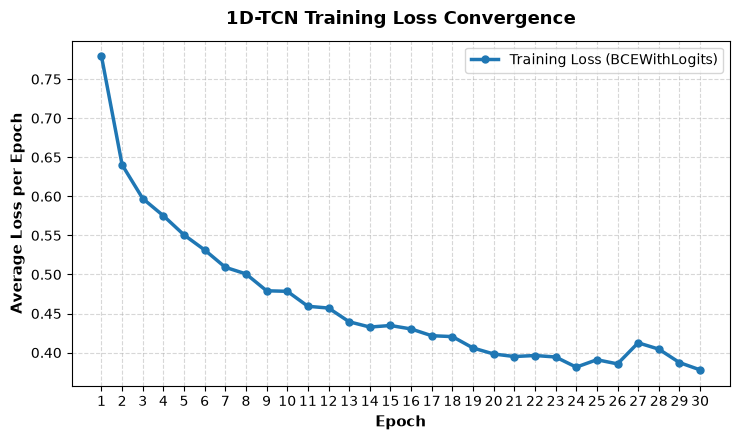

In [35]:
best_model_losses = best_tcn_losses

plt.figure(figsize=(7.5, 4.5))
plt.plot(range(1, len(best_model_losses) + 1), best_model_losses, 
         marker='o', color='#1f77b4', linewidth=2.5, markersize=5, label='Training Loss (BCEWithLogits)')

plt.title("1D-TCN Training Loss Convergence", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Epoch", fontsize=11, fontweight='bold')
plt.ylabel("Average Loss per Epoch", fontsize=11, fontweight='bold')
plt.xticks(range(1, len(best_model_losses) + 1))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()

# Save figures in the project-level output directory.
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "tcn_loss.png", dpi=300)
plt.show()

## Best model: test results

Select the trained model with the highest validation F1 from the comparisons
above, then evaluate it on the existing held-out test split. Reuse the fitted
normalizer, features, and model; model selection uses validation results only.

In [36]:
from sklearn.metrics import classification_report

best_validation_result = max(
    [best, best_xgb_res, best_tcn_res],
    key=lambda result: result.f1,
)
best_model = best_validation_result.model
print(f"Selected model: {best_validation_result.model_name}")
print(f"Validation F1: {best_validation_result.f1:.4f}")

if best_validation_result is best_tcn_res:
    test_dataset = COVIDSequenceDataset(
        X_test_norm, test_df, temporal_cols, static_cols,
    )
    test_loader = make_sequence_loader(test_dataset, batch_size=8)
    test_probs = predict_tcn(best_model, test_loader)
else:
    test_probs = best_model.predict_proba(X_test_norm)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)

final_results = ModelResults.evaluate(
    model_name=f"{best_validation_result.model_name} (Test)",
    model=best_model,
    hyperparameters=best_validation_result.hyperparameters,
    y_true=y_test,
    y_pred=test_preds,
    y_prob=test_probs,
)
print(final_results)
print(classification_report(
    y_test, test_preds, labels=[0, 1],
    target_names=["Stable/Decline (0)", "Surge (1)"], zero_division=0,
))

Selected model: XGBoost Classifier
Validation F1: 0.8062
   XGBoost Classifier (Test) EVALUATION
Hyperparameters:
   - max_depth: 3
   - learning_rate: 0.01
   - n_estimators: 100
--------------------------------------------------
Accuracy:  0.8401
Precision: 0.7624
Recall:    0.6928
F1-Score:  0.7260
ROC-AUC:   0.8715
PR-AUC:    0.7873

                    precision    recall  f1-score   support

Stable/Decline (0)       0.87      0.90      0.89      2662
         Surge (1)       0.76      0.69      0.73      1172

          accuracy                           0.84      3834
         macro avg       0.82      0.80      0.81      3834
      weighted avg       0.84      0.84      0.84      3834



## Error Analysis

In [37]:
test_errors = test_df.copy()
test_errors['predicted_surge'] = test_preds
test_errors['predicted_prob'] = test_probs

conditions = [
    (test_errors['target_surge'] == 1) & (test_errors['predicted_surge'] == 1),
    (test_errors['target_surge'] == 0) & (test_errors['predicted_surge'] == 0),
    (test_errors['target_surge'] == 0) & (test_errors['predicted_surge'] == 1),
    (test_errors['target_surge'] == 1) & (test_errors['predicted_surge'] == 0)
]
choices = ['True Positive (Hit)', 'True Negative (Correct Rejection)', 
           'False Positive (False Alarm)', 'False Negative (Missed Surge)']
test_errors['error_type'] = np.select(conditions, choices, default='Unknown')

error_summary = test_errors['error_type'].value_counts().reset_index()
error_summary.columns = ['Classification Result', 'Sample Count']
error_summary['Percentage (%)'] = (error_summary['Sample Count'] / len(test_errors)) * 100
print("\n--- OVERALL TEST SET ERROR DISTRIBUTION ---")
print(error_summary.to_string(index=False))

analysis_features = [
    "reproduction_rate", 
    "new_cases_smoothed_per_million", 
    "total_cases_per_million", 
    "active_harsh_measures_90d", 
    "days_since_last_harsh_measure",
    "predicted_prob"
]

profile_comparison = test_errors.groupby('error_type')[analysis_features].mean().round(2)
# Reorder rows for logical comparison
row_order = ['True Positive (Hit)', 'True Negative (Correct Rejection)', 
             'False Positive (False Alarm)', 'False Negative (Missed Surge)']
profile_comparison = profile_comparison.reindex([r for r in row_order if r in profile_comparison.index])

print("\n--- MEAN EPIDEMIOLOGICAL PROFILE BY ERROR TYPE ---")
print(profile_comparison.to_string())

# 5. Identify the most difficult country environments
print("\n--- TOP 5 COUNTRIES WITH MOST MISCLASSIFICATIONS IN TEST SET ---")
country_errors = test_errors[test_errors['error_type'].isin(['False Positive (False Alarm)', 'False Negative (Missed Surge)'])]
top_error_countries = country_errors['iso_code'].value_counts().head(5).reset_index()
top_error_countries.columns = ['ISO Code', 'Total Misclassifications']
print(top_error_countries.to_string(index=False))


--- OVERALL TEST SET ERROR DISTRIBUTION ---
            Classification Result  Sample Count  Percentage (%)
True Negative (Correct Rejection)          2409       62.832551
              True Positive (Hit)           812       21.178925
    False Negative (Missed Surge)           360        9.389671
     False Positive (False Alarm)           253        6.598852

--- MEAN EPIDEMIOLOGICAL PROFILE BY ERROR TYPE ---
                                   reproduction_rate  new_cases_smoothed_per_million  total_cases_per_million  active_harsh_measures_90d  days_since_last_harsh_measure  predicted_prob
error_type                                                                                                                                                                             
True Positive (Hit)                             1.25                          123.83                 11343.25                       2.52                          71.99            0.66
True Negative (Correct Rejectio

## XGBoost ablation study

Do the engineered policy features help? Keep the selected XGBoost hyperparameters
and the original training and test splits fixed. Train one additional model
without the two policy features, then compare it with the already-trained
XGBoost model. This is a separate experiment from the best-model test report.

In [38]:
from sklearn.base import clone

engineered_features = ["days_since_last_harsh_measure", "active_harsh_measures_90d"]
ablation_features = [col for col in feature_cols if col not in engineered_features]

# Reuse the chosen configuration; keep the original fitted model intact.
ablation_model = clone(best_xgb_res.model)
ablation_model.fit(X_train_norm[ablation_features], y_train)

test_probs_ablation = ablation_model.predict_proba(X_test_norm[ablation_features])[:, 1]
test_preds_ablation = (test_probs_ablation >= 0.5).astype(int)
ablation_results = ModelResults.evaluate(
    model_name="XGBoost (No Policy Features)",
    model=ablation_model,
    hyperparameters=best_xgb_res.hyperparameters,
    y_true=y_test,
    y_pred=test_preds_ablation,
    y_prob=test_probs_ablation,
)

xgb_test_probs = best_xgb_res.model.predict_proba(X_test_norm)[:, 1]
xgb_test_results = ModelResults.evaluate(
    model_name="XGBoost (All Features)",
    model=best_xgb_res.model,
    hyperparameters=best_xgb_res.hyperparameters,
    y_true=y_test,
    y_pred=(xgb_test_probs >= 0.5).astype(int),
    y_prob=xgb_test_probs,
)

print(xgb_test_results)
print(ablation_results)
print(f"Test F1 change without policy features: {ablation_results.f1 - xgb_test_results.f1:+.4f}")

   XGBoost (All Features) EVALUATION
Hyperparameters:
   - max_depth: 3
   - learning_rate: 0.01
   - n_estimators: 100
--------------------------------------------------
Accuracy:  0.8401
Precision: 0.7624
Recall:    0.6928
F1-Score:  0.7260
ROC-AUC:   0.8715
PR-AUC:    0.7873

   XGBoost (No Policy Features) EVALUATION
Hyperparameters:
   - max_depth: 3
   - learning_rate: 0.01
   - n_estimators: 100
--------------------------------------------------
Accuracy:  0.8362
Precision: 0.7361
Recall:    0.7235
F1-Score:  0.7298
ROC-AUC:   0.8712
PR-AUC:    0.7839

Test F1 change without policy features: +0.0038
